# 1

## 1(a)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, confusion_matrix, multilabel_confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, roc_curve, roc_auc_score
from joblib import Parallel, delayed, parallel_backend
from threadpoolctl import threadpool_limits

thread_limits = threadpool_limits(limits=1)
SEED = 552
DATA_PATH = Path("data/AnuranCalls/Frogs_MFCCs.csv")
data = pd.read_csv(DATA_PATH)
label_columns = ["Family", "Genus", "Species"]
feature_columns = [column for column in data.columns if column.startswith("MFCCs")]
X = data[feature_columns]
y = data[label_columns]
assert X.shape == (7195, 22)
assert not data.isna().any().any()
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=SEED)
display(pd.DataFrame({"Observations": [len(X), len(X_train), len(X_test)],
                      "Features": [X.shape[1]] * 3}, index=["Full data", "Training", "Test"]))
display(pd.concat({label: y_train[label].value_counts() for label in label_columns}, names=["Label", "Class"]).rename("Training count").to_frame())

,Observations,Features
Full data,7195,22
Training,5036,22
Test,2159,22


Training count
Label   Class                                 
Family  Leptodactylidae                   3088
        Hylidae                           1516
        Dendrobatidae                      384
        Bufonidae                           48
Genus   Adenomera                         2902
        Hypsiboas                         1107
        Ameerega                           384
        Dendropsophus                      221
        Leptodactylus                      186
        Scinax                             101
        Osteocephalus                       87
        Rhinella                            48
Species AdenomeraHylaedactylus            2433
        HypsiboasCordobae                  774
        AdenomeraAndre                     469
        Ameeregatrivittata                 384
        HypsiboasCinerascens               333
        HylaMinuta                         221
        LeptodactylusFuscus                186
        ScinaxRuber                        101
        OsteocephalusOophagus               87
        Rhinellagranulosa                   48

## 1(b)

### 1(b)i

For observation $i$, let $y_{ij}$ and $\hat y_{ij}$ be the true and predicted categorical labels, with $L=3$ output positions.

$$\mathrm{Exact\ match}=\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}(y_i=\hat y_i).$$
$$\mathrm{Average\ Hamming\ distance}=\frac{1}{n}\sum_{i=1}^{n}\sum_{j=1}^{L}\mathbf{1}(y_{ij}\ne\hat y_{ij}).$$
$$\mathrm{Hamming\ loss}=\frac{1}{nL}\sum_{i=1}^{n}\sum_{j=1}^{L}\mathbf{1}(y_{ij}\ne\hat y_{ij}),\qquad
\mathrm{Hamming\ score}=1-\mathrm{Hamming\ loss}.$$

Exact match requires all three labels to be correct. Hamming loss gives partial credit and measures the fraction of incorrectly predicted output positions; distance counts incorrect positions per observation. Here Hamming score denotes label-wise accuracy. Some sources call sample-wise Jaccard similarity a Hamming score, so that alternative is reported separately as **Sample Jaccard**. With three field-qualified labels in each true and predicted set and $m_i$ matches, Jaccard similarity is $m_i/(6-m_i)$. The three categorical positions, rather than all one-hot binary entries, define the main Hamming metrics.

In [2]:
def multilabel_metrics(truth, prediction):
    matches = np.asarray(truth) == np.asarray(prediction)
    correct = matches.sum(axis=1)
    return {"Exact match": matches.all(axis=1).mean(),
            "Average Hamming distance": (~matches).sum(axis=1).mean(),
            "Hamming score": matches.mean(),
            "Hamming loss": (~matches).mean(),
            "Sample Jaccard": np.mean(correct / (2 * matches.shape[1] - correct))}

models = {}
predictions = {}
decision_scores = {}
results = {}
cv_tables = {}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def train_independent(name, estimator, parameter_grid):
    fitted = {}
    rows = []
    for label in label_columns:
        search = GridSearchCV(estimator, parameter_grid, cv=cv, scoring="accuracy", n_jobs=4, refit=True, error_score="raise")
        with parallel_backend("threading"):
            search.fit(X_train, y_train[label])
        fitted[label] = search.best_estimator_
        rows.append({"Label": label, "Best CV accuracy": search.best_score_, **search.best_params_})
    models[name] = fitted
    predictions[name] = np.column_stack([fitted[label].predict(X_test) for label in label_columns])
    decision_scores[name] = {label: fitted[label].decision_function(X_test) for label in label_columns}
    results[name] = multilabel_metrics(y_test, predictions[name])
    cv_tables[name] = pd.DataFrame(rows).set_index("Label")
    display(cv_tables[name])
    display(pd.DataFrame({name: results[name]}).T)

### 1(b)ii

In [3]:
rbf_pipeline = Pipeline([("svm", OneVsRestClassifier(SVC(kernel="rbf", cache_size=256), n_jobs=1))])
rbf_grid = {"svm__estimator__C": [0.1, 1, 10, 100], "svm__estimator__gamma": [0.1, 1, 10]}
train_independent("Gaussian SVM (raw)", rbf_pipeline, rbf_grid)
rbf_parameters = cv_tables["Gaussian SVM (raw)"].copy()
rbf_parameters["Gaussian width sigma"] = np.sqrt(1 / (2 * rbf_parameters["svm__estimator__gamma"]))
display(rbf_parameters)

,Best CV accuracy,svm__estimator__C,svm__estimator__gamma
Label,,,
Family,0.992255,100,1
Genus,0.990271,10,1
Species,0.989473,10,1


,Exact match,Average Hamming distance,Hamming score,Hamming loss,Sample Jaccard
Gaussian SVM (raw),0.985642,0.030107,0.989964,0.010036,0.988698


,Best CV accuracy,svm__estimator__C,svm__estimator__gamma,Gaussian width sigma
Label,,,,
Family,0.992255,100,1,0.707107
Genus,0.990271,10,1,0.707107
Species,0.989473,10,1,0.707107


### 1(b)iii

In [4]:
linear_pipeline = Pipeline([("scale", StandardScaler()),
                            ("svm", LinearSVC(penalty="l1", dual=False, max_iter=100000, random_state=SEED))])
linear_grid = {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100]}
train_independent("L1 linear SVM", linear_pipeline, linear_grid)

,Best CV accuracy,svm__C
Label,,
Family,0.937849,1
Genus,0.954729,10
Species,0.958101,1


,Exact match,Average Hamming distance,Hamming score,Hamming loss,Sample Jaccard
L1 linear SVM,0.917554,0.157943,0.947352,0.052648,0.939


### 1(b)iv

The Gaussian SVM performed best, with a Hamming loss of 0.0100. The unweighted and class-weighted L1 SVMs had Hamming losses of 0.0526 and 0.0590, respectively. Class weighting improved mean macro recall from 0.8041 to 0.9019 but reduced overall accuracy, indicating a trade-off between minority-class recognition and overall performance.

In [5]:
balanced_pipeline = clone(linear_pipeline).set_params(svm__class_weight="balanced")
train_independent("L1 linear SVM (balanced)", balanced_pipeline, linear_grid)
comparison = pd.DataFrame(results).T
macro_recall = {}
for name, prediction in predictions.items():
    macro_recall[name] = np.mean([precision_recall_fscore_support(y_test[label], prediction[:, j], average="macro", zero_division=0)[1]
                                  for j, label in enumerate(label_columns)])
comparison["Mean macro recall"] = pd.Series(macro_recall)
display(comparison)

,Best CV accuracy,svm__C
Label,,
Family,0.931494,10
Genus,0.947979,10
Species,0.958101,1


,Exact match,Average Hamming distance,Hamming score,Hamming loss,Sample Jaccard
L1 linear SVM (balanced),0.903659,0.176934,0.941022,0.058978,0.930431


,Exact match,Average Hamming distance,Hamming score,Hamming loss,Sample Jaccard,Mean macro recall
Gaussian SVM (raw),0.985642,0.030107,0.989964,0.010036,0.988698,0.967940
L1 linear SVM,0.917554,0.157943,0.947352,0.052648,0.939000,0.804080
L1 linear SVM (balanced),0.903659,0.176934,0.941022,0.058978,0.930431,0.901918


# 2

## 2(a)

Selection criterion: maximize Calinski-Harabasz score using all 7,195 rows and 22 original MFCC features.
k=1 is fitted and its inertia is recorded; CH is undefined for one cluster, so selection compares k=2,...,50.


,Run,k,CH score
0,1,2,3680.741349
1,2,2,3680.741349
2,3,2,3680.741349
3,4,2,3680.741349
4,5,2,3680.741349
5,6,2,3680.741349
6,7,2,3680.741349
7,8,2,3680.741349
8,9,2,3680.741349
9,10,2,3680.741349


,Runs
Selected k,
2,50


,Run,k,CH score,Inertia
0,1,1,NaN,3727.524167
1,1,2,3680.741349,2465.764126
2,1,3,3157.636137,1984.738845
3,1,4,2708.049963,1750.203327
4,1,5,2628.953028,1513.678028


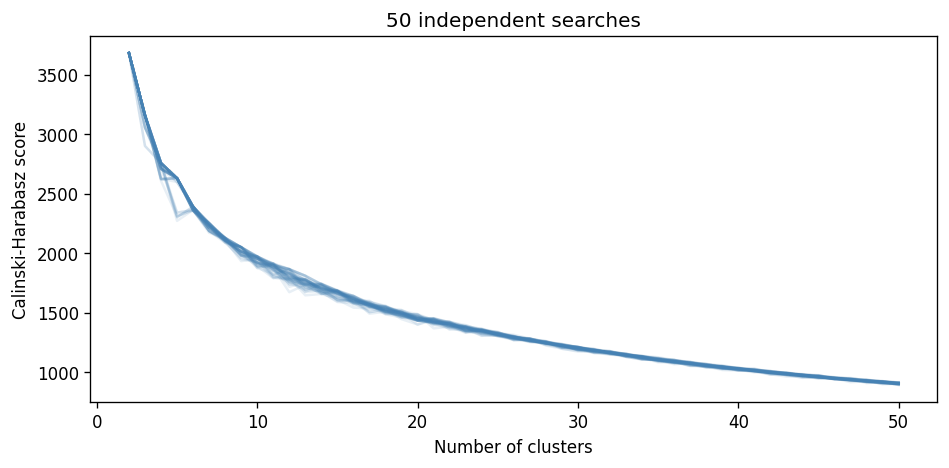

In [8]:
X_cluster = X.to_numpy()

def select_clusters(seed):
    rows = []
    best_score = -np.inf
    best_labels = None
    best_k = None
    for k in range(1, 51):
        fitted = KMeans(n_clusters=k, n_init=3, max_iter=300, random_state=seed).fit(X_cluster)
        score = np.nan if k == 1 else calinski_harabasz_score(X_cluster, fitted.labels_)
        rows.append({"Run": seed - SEED + 1, "k": k, "CH score": score, "Inertia": fitted.inertia_})
        if k > 1 and score > best_score:
            best_score = score
            best_labels = fitted.labels_.copy()
            best_k = k
    return {"Run": seed - SEED + 1, "k": best_k, "CH score": best_score,
            "Assignments": best_labels, "Search": rows}

cluster_runs = Parallel(n_jobs=4, prefer="threads")(delayed(select_clusters)(SEED + run) for run in range(50))
search_results = pd.DataFrame([row for run in cluster_runs for row in run["Search"]])
selected_k = pd.DataFrame([{key: run[key] for key in ["Run", "k", "CH score"]} for run in cluster_runs])
display(selected_k)
display(selected_k["k"].value_counts().sort_index().rename_axis("Selected k").rename("Runs").to_frame())
print("Selection criterion: maximize Calinski-Harabasz score using all 7,195 rows and 22 original MFCC features.")
print("k=1 is fitted and its inertia is recorded; CH is undefined for one cluster, so selection compares k=2,...,50.")
display(search_results.head())
fig, ax = plt.subplots(figsize=(8, 4))
for _, frame in search_results.groupby("Run"):
    ax.plot(frame["k"], frame["CH score"], alpha=0.12, color="steelblue")
ax.set(xlabel="Number of clusters", ylabel="Calinski-Harabasz score", title="50 independent searches")
fig.tight_layout()
display(fig)
plt.close(fig)

## 2(b)

In [9]:
majority_tables = []
cluster_predictions = []
for run in cluster_runs:
    assignments = run["Assignments"]
    assigned_labels = np.empty(y.shape, dtype=object)
    for cluster in range(run["k"]):
        mask = assignments == cluster
        majority = [y.loc[mask, label].mode().iloc[0] for label in label_columns]
        assigned_labels[mask] = majority
        majority_tables.append({"Run": run["Run"], "Cluster": cluster, "Size": int(mask.sum()),
                                 **dict(zip(label_columns, majority))})
    cluster_predictions.append(assigned_labels)
majority_labels = pd.DataFrame(majority_tables)
with pd.option_context("display.max_rows", None):
    display(majority_labels)

,Run,Cluster,Size,Family,Genus,Species
0,1,0,3597,Hylidae,Hypsiboas,HypsiboasCordobae
1,1,1,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
2,2,0,3597,Hylidae,Hypsiboas,HypsiboasCordobae
3,2,1,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
4,3,0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
5,3,1,3597,Hylidae,Hypsiboas,HypsiboasCordobae
6,4,0,3597,Hylidae,Hypsiboas,HypsiboasCordobae
7,4,1,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
8,5,0,3597,Hylidae,Hypsiboas,HypsiboasCordobae
9,5,1,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


## 2(c)

In [10]:
monte_carlo = pd.DataFrame([{"Run": run["Run"], "k": run["k"], **multilabel_metrics(y, prediction)}
                            for run, prediction in zip(cluster_runs, cluster_predictions)])
with pd.option_context("display.max_rows", 60, "display.max_columns", 10):
    display(monte_carlo)
metric_columns = ["Average Hamming distance", "Hamming score", "Hamming loss", "Exact match", "Sample Jaccard"]
monte_carlo_summary = monte_carlo[metric_columns].agg(["mean", "std"]).T
monte_carlo_summary.columns = ["Mean over 50 runs", "Sample standard deviation (ddof=1)"]
display(monte_carlo_summary)
assert len(monte_carlo) == 50
assert np.allclose(monte_carlo["Average Hamming distance"], 3 * monte_carlo["Hamming loss"])
assert np.allclose(monte_carlo["Hamming score"] + monte_carlo["Hamming loss"], 1)

,Run,k,Exact match,Average Hamming distance,Hamming score,Hamming loss,Sample Jaccard
0,1,2,0.636136,0.895622,0.701459,0.298541,0.68189
1,2,2,0.636136,0.895622,0.701459,0.298541,0.68189
2,3,2,0.636136,0.895622,0.701459,0.298541,0.68189
3,4,2,0.636136,0.895622,0.701459,0.298541,0.68189
4,5,2,0.636136,0.895622,0.701459,0.298541,0.68189
5,6,2,0.636136,0.895622,0.701459,0.298541,0.68189
6,7,2,0.636136,0.895622,0.701459,0.298541,0.68189
7,8,2,0.636136,0.895622,0.701459,0.298541,0.68189
8,9,2,0.636136,0.895622,0.701459,0.298541,0.68189
9,10,2,0.636136,0.895622,0.701459,0.298541,0.68189


,Mean over 50 runs,Sample standard deviation (ddof=1)
Average Hamming distance,0.895622,1.121495e-16
Hamming score,0.701459,1.121495e-16
Hamming loss,0.298541,5.607473e-17
Exact match,0.636136,1.121495e-16
Sample Jaccard,0.681890,1.121495e-16


## 3

![ISLR 12.6.2 Solution](IMG_7050.jpeg)